# Etapa 3 — ajuste interativo da dieta do Notebook 2

## Propósito

Receber a dieta criada pelo nosso otimizador no Notebook 2 e permitir que cada ingrediente seja ajustado por duas barras próprias:

- **quantidade:** kg de matéria seca por vaca e por dia;
- **preço:** USD por kg de matéria seca.

O notebook verifica as cinco restrições antes da simulação, converte as quantidades em percentuais, aplica a dieta ao RuFaS, gera a fazenda com a mesma semente e compara produção de leite, custo, receita e margem com o resultado original do nosso otimizador.

> **Dependência obrigatória:** execute o Notebook 2 por completo antes desta etapa.

## Índice

1. **Preparação** — carrega ferramentas e caminhos compartilhados.
2. **Linha de base** — recebe fazenda, semente, dieta e restrições do Notebook 2.
3. **Barras por ingrediente** — ajusta quantidade e preço individualmente.
4. **Preparação da dieta ajustada** — calcula percentuais, custo e restrições planejadas.
5. **Aplicação no RuFaS** — gera a fazenda e simula a dieta ajustada.
6. **População inicial** — confirma que o sorteio inicial é o mesmo.
7. **Restrições realizadas** — verifica a ração média efetivamente consumida.
8. **Desempenho** — compara leite, custo, receita e margem com o otimizador.
9. **Composição e gráficos** — mostra como a dieta e os resultados mudaram.

## 1. Preparação

**O que faz:** importa as classes usadas para montar uma dieta fixa, executar o RuFaS e comparar os resultados.

In [28]:
import copy
import json
import os
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rufas_project import (
    calculate_economics, evaluate_ration_against_main_requirements,
    load_custom_baseline_artifact, load_result, submit_simulation,
    summarize_lactating_ration, validate_simulation_config, wait_for_simulation,
)

SHARED_ROOT = Path(os.getenv('SHARED_ROOT', '/workspace/shared'))
BASELINE_ARTIFACT_PATH = SHARED_ROOT / 'exports' / 'notebook2_custom_baseline.json'
ADJUSTMENTS_PATH = SHARED_ROOT / 'exports' / 'notebook3_manual_adjustments.json'
FEED_LIBRARY_CANDIDATES = [
    Path('/workspace/data/NASEM_Comp_with_TDN.csv'),
    Path('../RuFaS/input/data/feed/NASEM_Comp_with_TDN.csv'),
]
FEED_LIBRARY_PATH = next((path for path in FEED_LIBRARY_CANDIDATES if path.exists()), None)
if FEED_LIBRARY_PATH is None:
    raise FileNotFoundError('Biblioteca nutricional do RuFaS não encontrada.')

TABLE_STYLES = [
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px 0')]},
    {'selector': 'th', 'props': [('background-color', '#256a4b'), ('color', 'white'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('padding', '7px 12px'), ('border-bottom', '1px solid #e5e7eb')]},
]

def show_table(frame, caption, hide_index=True, formatter=None):
    styled = frame.style.set_caption(caption).set_table_styles(TABLE_STYLES)
    if hide_index:
        styled = styled.hide(axis='index')
    if formatter:
        styled = styled.format(formatter)
    display(styled)

def format_pt_br(value, decimals=2, suffix=''):
    if pd.isna(value):
        return '—'
    formatted = f'{value:,.{decimals}f}'.replace(',', 'TEMP').replace('.', ',').replace('TEMP', '.')
    return f'{formatted}{suffix}'

names_pt = {
    23: 'Farinha de sangue', 44: 'Milho seco moído', 50: 'Silagem de milho',
    104: 'Mistura gramínea/leguminosa', 110: 'Silagem de leguminosa',
    301: 'Mistura mineral', 302: 'Mistura de subprodutos',
}
print(f'Linha de base esperada em: {BASELINE_ARTIFACT_PATH}')

Linha de base esperada em: /workspace/shared/exports/notebook2_custom_baseline.json


## 2. Linha de base recebida do Notebook 2

**O que faz:** carrega exatamente a fazenda, a semente, os cinco mínimos, os preços e a dieta calculada pelo nosso otimizador.

In [29]:
baseline = load_custom_baseline_artifact(BASELINE_ARTIFACT_PATH)
reference = baseline.reference
requirements = baseline.requirements
baseline_solution = baseline.solution
baseline_scenario = baseline.scenario

transfer_table = pd.DataFrame([
    ('Execução-base do Notebook 2', baseline.job_id),
    ('Semente', reference.random_seed),
    ('Período', f'{reference.simulation_days} dias'),
    ('Vacas configuradas', reference.herd.cow_num),
    ('Custo objetivo', f'{baseline_solution.objective_usd_per_cow_day:.4f} USD/vaca/dia'),
], columns=['Item recebido', 'Valor'])
show_table(transfer_table, 'Linha de base do nosso otimizador')

baseline_ration = baseline_solution.ration.copy()
baseline_ration['Ingrediente'] = baseline_ration['feed_type'].map(names_pt)
baseline_display = baseline_ration.rename(columns={
    'feed_type': 'ID', 'kg_dm_per_cow_day': 'Quantidade (kg MS/vaca/dia)',
    'percentage_dm': 'Participação (%)', 'price_usd_per_kg_dm': 'Preço (USD/kg MS)',
    'cost_usd_per_cow_day': 'Custo (USD/vaca/dia)',
})[['ID', 'Ingrediente', 'Quantidade (kg MS/vaca/dia)', 'Participação (%)',
    'Preço (USD/kg MS)', 'Custo (USD/vaca/dia)']]
show_table(
    baseline_display, 'Dieta criada pelo nosso otimizador no Notebook 2',
    formatter={column: (lambda value: format_pt_br(value, 4)) for column in baseline_display.columns if column not in ['ID', 'Ingrediente']},
)

Item recebido,Valor
Execução-base do Notebook 2,35880ae0-b2c7-4610-802b-f7211dd71e10
Semente,100
Período,30 dias
Vacas configuradas,20
Custo objetivo,4.5226 USD/vaca/dia


ID,Ingrediente,Quantidade (kg MS/vaca/dia),Participação (%),Preço (USD/kg MS),Custo (USD/vaca/dia)
23,Farinha de sangue,"0,0000","0,0000","1,8142","0,0000"
44,Milho seco moído,"0,0000","0,0000","0,2730","0,0000"
50,Silagem de milho,"8,7955","35,0388","0,1209","1,0638"
104,Mistura gramínea/leguminosa,"10,3277","41,1425","0,1703","1,7585"
110,Silagem de leguminosa,"0,0000","0,0000","0,2061","0,0000"
301,Mistura mineral,"0,0000","0,0000","1,1225","0,0000"
302,Mistura de subprodutos,"5,9790","23,8188","0,2844","1,7003"


## 3. Barras de quantidade e preço por ingrediente

**O que faz:** cada linha controla um ingrediente. A barra verde representa a quantidade planejada e a barra amarela representa o preço. Ingredientes que o otimizador zerou podem ser incluídos aumentando sua quantidade.

1. Ajuste as barras.
2. Clique em **Salvar ajustes**.
3. Execute novamente todas as células abaixo desta seção.

Os valores salvos permanecem mesmo se esta célula for executada novamente ou se o kernel for reiniciado. O botão **Restaurar otimizador** recoloca os valores originais nas barras; depois dele, clique em **Salvar ajustes** para confirmar a restauração.

In [31]:
# BLOCO 1 — Recupera ajustes persistidos anteriormente
saved_adjustments = {}
if ADJUSTMENTS_PATH.exists():
    saved_adjustments = json.loads(ADJUSTMENTS_PATH.read_text(encoding='utf-8')).get('ingredients', {})

# BLOCO 2 — Cria os controles apenas uma vez no kernel
expected_feed_ids = {int(value) for value in baseline_ration['feed_type']}
widgets_already_created = (
    'quantity_sliders' in globals() and 'price_sliders' in globals()
    and set(quantity_sliders) == expected_feed_ids and set(price_sliders) == expected_feed_ids
)
if not widgets_already_created:
    quantity_sliders = {}
    price_sliders = {}
    for item in baseline_ration.itertuples(index=False):
        feed_id = int(item.feed_type)
        saved = saved_adjustments.get(str(feed_id), {})
        initial_quantity = float(saved.get('quantity_kg_dm_per_cow_day', item.kg_dm_per_cow_day))
        initial_price = float(saved.get('price_usd_per_kg_dm', item.price_usd_per_kg_dm))
        quantity_sliders[feed_id] = widgets.FloatSlider(
            value=initial_quantity, min=0.0, max=max(30.0, initial_quantity * 1.2), step=0.1,
            readout_format='.2f', continuous_update=False,
            layout=widgets.Layout(width='390px'), style={'handle_color': '#256a4b'},
        )
        price_sliders[feed_id] = widgets.FloatSlider(
            value=initial_price, min=0.0,
            max=max(0.50, float(item.price_usd_per_kg_dm) * 3, initial_price * 1.2), step=0.001,
            readout_format='.4f', continuous_update=False,
            layout=widgets.Layout(width='390px'), style={'handle_color': '#d59b2d'},
        )

# BLOCO 3 — Monta a apresentação reutilizando os controles existentes
rows = [widgets.HBox([
    widgets.HTML('<b style="display:block;width:230px">Ingrediente</b>'),
    widgets.HTML('<b style="display:block;width:390px">Quantidade (kg MS/vaca/dia)</b>'),
    widgets.HTML('<b>Preço (USD/kg MS)</b>'),
]) ]

for item in baseline_ration.itertuples(index=False):
    feed_id = int(item.feed_type)
    rows.append(widgets.HBox([
        widgets.HTML(f'<span style="display:block;width:230px"><b>{feed_id}</b> — {names_pt[feed_id]}</span>'),
        quantity_sliders[feed_id], price_sliders[feed_id],
    ]))

# BLOCO 4 — Botões para persistir ou restaurar os valores
if 'adjustment_status_output' not in globals():
    adjustment_status_output = widgets.Output()

if 'save_adjustments_button' not in globals():
    save_adjustments_button = widgets.Button(
        description='Salvar ajustes', button_style='success', icon='save',
    )
    def save_adjustments(_):
        payload = {
            'schema_version': 1,
            'ingredients': {
                str(feed_id): {
                    'quantity_kg_dm_per_cow_day': float(quantity_sliders[feed_id].value),
                    'price_usd_per_kg_dm': float(price_sliders[feed_id].value),
                }
                for feed_id in sorted(quantity_sliders)
            },
        }
        ADJUSTMENTS_PATH.parent.mkdir(parents=True, exist_ok=True)
        ADJUSTMENTS_PATH.write_text(json.dumps(payload, indent=2, ensure_ascii=False), encoding='utf-8')
        with adjustment_status_output:
            adjustment_status_output.clear_output()
            print(f'Ajustes salvos em: {ADJUSTMENTS_PATH}')
    save_adjustments_button.on_click(save_adjustments)

if 'restore_baseline_button' not in globals():
    restore_baseline_button = widgets.Button(
        description='Restaurar otimizador', button_style='warning', icon='undo',
    )
    def restore_baseline(_):
        for item in baseline_ration.itertuples(index=False):
            feed_id = int(item.feed_type)
            quantity_sliders[feed_id].value = float(item.kg_dm_per_cow_day)
            price_sliders[feed_id].value = float(item.price_usd_per_kg_dm)
        with adjustment_status_output:
            adjustment_status_output.clear_output()
            print('Valores do otimizador restaurados nas barras. Clique em Salvar ajustes para persistir.')
    restore_baseline_button.on_click(restore_baseline)

display(widgets.VBox(rows))
display(widgets.HBox([save_adjustments_button, restore_baseline_button]))
display(adjustment_status_output)
if saved_adjustments:
    print(f'Ajustes persistidos carregados de: {ADJUSTMENTS_PATH}')
else:
    print('Nenhum ajuste salvo; usando os valores do otimizador.')

Output(outputs=({'name': 'stdout', 'text': 'Ajustes salvos em: /workspace/shared/exports/notebook3_manual_adju…

Ajustes persistidos carregados de: /workspace/shared/exports/notebook3_manual_adjustments.json


## 4. Preparação e validação da dieta ajustada

**O que faz:** lê as barras, calcula o total de matéria seca, converte as quantidades em percentuais para o RuFaS, calcula o custo planejado e verifica os cinco pisos nutricionais.

In [32]:
manual_rows = []
baseline_by_id = baseline_ration.set_index('feed_type')
for ingredient in reference.diet.ingredients:
    feed_id = ingredient.feed_type
    quantity = float(quantity_sliders[feed_id].value)
    price = float(price_sliders[feed_id].value)
    manual_rows.append({
        'feed_type': feed_id, 'name': ingredient.name,
        'kg_dm_per_cow_day': quantity, 'price_usd_per_kg_dm': price,
    })
manual_ration = pd.DataFrame(manual_rows)
total_manual_dmi = manual_ration['kg_dm_per_cow_day'].sum()
if total_manual_dmi <= 0:
    raise ValueError('A dieta precisa conter pelo menos um ingrediente com quantidade positiva.')
manual_ration['percentage_dm'] = manual_ration['kg_dm_per_cow_day'] / total_manual_dmi * 100
manual_ration['cost_usd_per_cow_day'] = manual_ration['kg_dm_per_cow_day'] * manual_ration['price_usd_per_kg_dm']
manual_planned_cost = manual_ration['cost_usd_per_cow_day'].sum()

adjusted_scenario = copy.deepcopy(baseline_scenario)
adjusted_scenario.name = 'fase3_dieta_ajustada_manualmente'
for ingredient in adjusted_scenario.diet.ingredients:
    row = manual_ration.loc[manual_ration['feed_type'] == ingredient.feed_type].iloc[0]
    ingredient.ration_percentage = float(row['percentage_dm'])
    ingredient.purchased_feed_cost_usd_per_kg_dm = float(row['price_usd_per_kg_dm'])
validate_simulation_config(adjusted_scenario)

manual_display = manual_ration.copy()
manual_display['Ingrediente'] = manual_display['feed_type'].map(names_pt)
manual_display['Quantidade do otimizador'] = manual_display['feed_type'].map(baseline_by_id['kg_dm_per_cow_day'])
manual_display['Preço do otimizador'] = manual_display['feed_type'].map(baseline_by_id['price_usd_per_kg_dm'])
manual_display = manual_display.rename(columns={
    'feed_type': 'ID', 'kg_dm_per_cow_day': 'Quantidade ajustada',
    'percentage_dm': 'Participação ajustada (%)',
    'price_usd_per_kg_dm': 'Preço ajustado',
    'cost_usd_per_cow_day': 'Custo ajustado (USD/vaca/dia)',
})[['ID', 'Ingrediente', 'Quantidade do otimizador', 'Quantidade ajustada',
    'Participação ajustada (%)', 'Preço do otimizador', 'Preço ajustado',
    'Custo ajustado (USD/vaca/dia)']]
show_table(
    manual_display, f'Dieta ajustada — {total_manual_dmi:.2f} kg MS/vaca/dia; custo planejado {manual_planned_cost:.4f} USD/vaca/dia',
    formatter={column: (lambda value: format_pt_br(value, 4)) for column in manual_display.columns if column not in ['ID', 'Ingrediente']},
)

planned_constraints = evaluate_ration_against_main_requirements(
    manual_ration, FEED_LIBRARY_PATH, requirements,
).rename(columns={
    'constraint': 'Restrição', 'value': 'Valor planejado', 'minimum': 'Mínimo',
    'unit': 'Unidade', 'satisfied': 'Atendida',
})
planned_constraints['Atendida'] = planned_constraints['Atendida'].map({True: 'Sim', False: 'Não'})
show_table(
    planned_constraints, 'Restrições da dieta ajustada antes da simulação',
    formatter={'Valor planejado': lambda value: format_pt_br(value, 3), 'Mínimo': lambda value: format_pt_br(value, 3)},
)

ID,Ingrediente,Quantidade do otimizador,Quantidade ajustada,Participação ajustada (%),Preço do otimizador,Preço ajustado,Custo ajustado (USD/vaca/dia)
23,Farinha de sangue,"0,0000","8,2000","13,0348","1,8142","1,2910","10,5862"
44,Milho seco moído,"0,0000","8,8000","13,9886","0,2730","0,3570","3,1416"
50,Silagem de milho,"8,7955","9,3980","14,9392","0,1209","0,0800","0,7518"
104,Mistura gramínea/leguminosa,"10,3277","8,0079","12,7295","0,1703","0,0910","0,7287"
110,Silagem de leguminosa,"0,0000","13,2000","20,9829","0,2061","0,2800","3,6960"
301,Mistura mineral,"0,0000","8,8000","13,9886","1,1225","0,6090","5,3592"
302,Mistura de subprodutos,"5,9790","6,5023","10,3362","0,2844","0,1790","1,1639"


Restrição,Valor planejado,Mínimo,Unidade,Atendida
Energia (TDN),"36,529","16,298",kg TDN/vaca/dia,Sim
Proteína bruta,"15,299","4,075",kg PB/vaca/dia,Sim
Cálcio,"1.683,453","171,855",g/vaca/dia,Sim
Fósforo,"393,279","96,071",g/vaca/dia,Sim
Fibra (NDF),"16,060","9,982",kg NDF/vaca/dia,Sim


## 5. Aplicação da dieta ajustada no RuFaS

**O que faz:** carrega a simulação original do Notebook 2 e executa uma nova simulação com a dieta ajustada. A fazenda, a semente e o período são mantidos.

In [33]:
try:
    baseline_result = load_result(baseline.job_id, SHARED_ROOT)
    print(f'Linha de base carregada do Notebook 2: {baseline.job_id}')
except FileNotFoundError:
    print('Resultado-base indisponível; executando novamente a dieta do otimizador.')
    baseline_job = submit_simulation(baseline_scenario, SHARED_ROOT)
    wait_for_simulation(baseline_job, SHARED_ROOT, timeout_seconds=1800)
    baseline_result = load_result(baseline_job, SHARED_ROOT)

adjusted_job = submit_simulation(adjusted_scenario, SHARED_ROOT)
wait_for_simulation(adjusted_job, SHARED_ROOT, timeout_seconds=1800)
adjusted_result = load_result(adjusted_job, SHARED_ROOT)
print(f'Dieta ajustada simulada com sucesso: {adjusted_job}')

Linha de base carregada do Notebook 2: 35880ae0-b2c7-4610-802b-f7211dd71e10
Aguardando: Solicitação gravada; aguardando o worker do RuFaS
Em execução: Executando o main.py do RuFaS
Concluída: Simulação concluída e resultados processados
Dieta ajustada simulada com sucesso: c05b8cbb-aea8-4006-b289-33f8e6fa4e42


## 6. Fazenda e população inicial

**O que faz:** apresenta a população gerada e confirma se a dieta ajustada foi aplicada ao mesmo sorteio inicial usado pelo nosso otimizador.

In [34]:
base_population = baseline_result['initial_population']
adjusted_population = adjusted_result['initial_population']
signature_keys = [
    'random_seed', 'breed', 'number_of_calves', 'number_of_heifer_is',
    'number_of_heifer_iis', 'number_of_heifer_iiis', 'number_of_cows',
    'number_of_lactating_cows', 'number_of_dry_cows',
]
same_population = all(base_population.get(key) == adjusted_population.get(key) for key in signature_keys)
stage_keys = ['number_of_calves', 'number_of_heifer_is', 'number_of_heifer_iis', 'number_of_heifer_iiis', 'number_of_cows']
total_animals = sum(base_population.get(key) or 0 for key in stage_keys)
farm_table = pd.DataFrame([
    ('Semente', str(base_population['random_seed']), str(adjusted_population['random_seed'])),
    ('Raça', base_population['breed'], adjusted_population['breed']),
    ('Total de animais', f'{total_animals:.0f} animais', f"{sum(adjusted_population.get(key) or 0 for key in stage_keys):.0f} animais"),
    ('Bezerras', f"{base_population['number_of_calves']:.0f} animais", f"{adjusted_population['number_of_calves']:.0f} animais"),
    ('Novilhas I', f"{base_population['number_of_heifer_is']:.0f} animais", f"{adjusted_population['number_of_heifer_is']:.0f} animais"),
    ('Novilhas II', f"{base_population['number_of_heifer_iis']:.0f} animais", f"{adjusted_population['number_of_heifer_iis']:.0f} animais"),
    ('Novilhas III', f"{base_population['number_of_heifer_iiis']:.0f} animais", f"{adjusted_population['number_of_heifer_iiis']:.0f} animais"),
    ('Vacas', f"{base_population['number_of_cows']:.0f} animais", f"{adjusted_population['number_of_cows']:.0f} animais"),
    ('Vacas em lactação', f"{base_population['number_of_lactating_cows']:.0f} animais", f"{adjusted_population['number_of_lactating_cows']:.0f} animais"),
    ('Vacas secas', f"{base_population['number_of_dry_cows']:.0f} animais", f"{adjusted_population['number_of_dry_cows']:.0f} animais"),
], columns=['Característica', 'Otimizador — Notebook 2', 'Dieta ajustada'])
show_table(farm_table, 'População inicial das duas simulações')
print(f'Mesma população inicial: {"SIM" if same_population else "NÃO"}')

Característica,Otimizador — Notebook 2,Dieta ajustada
Semente,100,100
Raça,Holstein,Holstein
Total de animais,114 animais,114 animais
Bezerras,8 animais,8 animais
Novilhas I,44 animais,44 animais
Novilhas II,38 animais,38 animais
Novilhas III,5 animais,5 animais
Vacas,19 animais,19 animais
Vacas em lactação,15 animais,15 animais
Vacas secas,4 animais,4 animais


Mesma população inicial: SIM


## 7. Restrições após a aplicação da dieta

**O que faz:** calcula o fornecimento nutricional da ração média efetivamente registrada pelo RuFaS e compara com os mesmos cinco mínimos do Notebook 2.

In [35]:
baseline_actual_ration, baseline_totals = summarize_lactating_ration(baseline_result, baseline_scenario)
adjusted_actual_ration, adjusted_totals = summarize_lactating_ration(adjusted_result, adjusted_scenario)
realized_constraints = evaluate_ration_against_main_requirements(
    adjusted_actual_ration, FEED_LIBRARY_PATH, requirements,
).rename(columns={
    'constraint': 'Restrição', 'value': 'Valor realizado', 'minimum': 'Mínimo',
    'unit': 'Unidade', 'satisfied': 'Atendida',
})
realized_constraints['Atendida'] = realized_constraints['Atendida'].map({True: 'Sim', False: 'Não'})
show_table(
    realized_constraints, 'Restrições da dieta efetivamente consumida',
    formatter={'Valor realizado': lambda value: format_pt_br(value, 3), 'Mínimo': lambda value: format_pt_br(value, 3)},
)
all_realized_constraints = (realized_constraints['Atendida'] == 'Sim').all()
print(f'Todas as cinco restrições foram atendidas após a simulação: {"SIM" if all_realized_constraints else "NÃO"}')

Restrição,Valor realizado,Mínimo,Unidade,Atendida
Energia (TDN),"16,086","16,298",kg TDN/vaca/dia,Não
Proteína bruta,"6,484","4,075",kg PB/vaca/dia,Sim
Cálcio,"678,684","171,855",g/vaca/dia,Sim
Fósforo,"164,158","96,071",g/vaca/dia,Sim
Fibra (NDF),"7,453","9,982",kg NDF/vaca/dia,Não


Todas as cinco restrições foram atendidas após a simulação: NÃO


## 8. Produção de leite e custo comparados com o otimizador

**O que faz:** compara a dieta ajustada com a execução original do nosso otimizador. O custo planejado usa as quantidades das barras; o custo realizado usa o consumo registrado pelo RuFaS.

In [36]:
baseline_economics = calculate_economics(baseline_result, baseline_scenario)
adjusted_economics = calculate_economics(adjusted_result, adjusted_scenario)
density = reference.economics.milk_density_kg_per_liter

performance = pd.DataFrame([
    {
        'Cenário': 'Nosso otimizador — Notebook 2',
        'Custo planejado (USD/vaca/dia)': baseline_solution.objective_usd_per_cow_day,
        'Custo realizado (USD/vaca/dia)': baseline_totals['average_cost_usd_per_cow_day'],
        'Leite total (kg)': baseline_result['metrics']['total_milk_kg'],
        'Leite total (L)': baseline_result['metrics']['total_milk_kg'] / density,
        'Leite médio (kg/dia)': baseline_result['metrics']['average_daily_milk_kg'],
        'Custo alimentar (USD)': baseline_economics['total_lactating_feed_cost'],
        'Receita do leite (USD)': baseline_economics['total_milk_revenue'],
        'Margem alimentar (USD)': baseline_economics['margin_over_lactating_feed_cost'],
    },
    {
        'Cenário': 'Dieta ajustada nas barras',
        'Custo planejado (USD/vaca/dia)': manual_planned_cost,
        'Custo realizado (USD/vaca/dia)': adjusted_totals['average_cost_usd_per_cow_day'],
        'Leite total (kg)': adjusted_result['metrics']['total_milk_kg'],
        'Leite total (L)': adjusted_result['metrics']['total_milk_kg'] / density,
        'Leite médio (kg/dia)': adjusted_result['metrics']['average_daily_milk_kg'],
        'Custo alimentar (USD)': adjusted_economics['total_lactating_feed_cost'],
        'Receita do leite (USD)': adjusted_economics['total_milk_revenue'],
        'Margem alimentar (USD)': adjusted_economics['margin_over_lactating_feed_cost'],
    },
]).set_index('Cenário')
show_table(
    performance, 'Desempenho produtivo e econômico', hide_index=False,
    formatter=lambda value: format_pt_br(value, 2),
)

baseline_values = performance.loc['Nosso otimizador — Notebook 2']
adjusted_values = performance.loc['Dieta ajustada nas barras']
comparison_rows = []
for indicator in performance.columns:
    base_value = baseline_values[indicator]
    adjusted_value = adjusted_values[indicator]
    comparison_rows.append((indicator, base_value, adjusted_value, adjusted_value - base_value, (adjusted_value / base_value - 1) * 100))
differences = pd.DataFrame(comparison_rows, columns=[
    'Indicador', 'Otimizador', 'Dieta ajustada', 'Diferença absoluta', 'Diferença (%)',
])
show_table(
    differences, 'Diferenças em relação ao nosso otimizador',
    formatter={
        'Otimizador': lambda value: format_pt_br(value, 2),
        'Dieta ajustada': lambda value: format_pt_br(value, 2),
        'Diferença absoluta': lambda value: format_pt_br(value, 2),
        'Diferença (%)': lambda value: format_pt_br(value, 2, '%'),
    },
)

,Custo planejado (USD/vaca/dia),Custo realizado (USD/vaca/dia),Leite total (kg),Leite total (L),Leite médio (kg/dia),Custo alimentar (USD),Receita do leite (USD),Margem alimentar (USD)
Cenário,,,,,,,,
Nosso otimizador — Notebook 2,"4,52","5,22","22.256,62","21.608,37","741,89","2.910,15","9.666,29","6.756,14"
Dieta ajustada nas barras,"25,43","10,37","22.253,60","21.605,44","741,79","5.776,14","9.664,98","3.888,84"


Indicador,Otimizador,Dieta ajustada,Diferença absoluta,Diferença (%)
Custo planejado (USD/vaca/dia),"4,52","25,43","20,90","462,23%"
Custo realizado (USD/vaca/dia),"5,22","10,37","5,15","98,48%"
Leite total (kg),"22.256,62","22.253,60","-3,02","-0,01%"
Leite total (L),"21.608,37","21.605,44","-2,94","-0,01%"
Leite médio (kg/dia),"741,89","741,79","-0,10","-0,01%"
Custo alimentar (USD),"2.910,15","5.776,14","2.865,99","98,48%"
Receita do leite (USD),"9.666,29","9.664,98","-1,31","-0,01%"
Margem alimentar (USD),"6.756,14","3.888,84","-2.867,31","-42,44%"


## 9. Composição e visualização

**O que faz:** mostra a composição efetivamente simulada e os principais resultados de produção e custo.

Ingrediente,Nosso otimizador (%),Dieta ajustada (%)
Farinha de sangue,"0,00%","11,63%"
Milho seco moído,"0,00%","12,48%"
Silagem de milho,"32,39%","16,29%"
Mistura gramínea/leguminosa,"45,59%","13,88%"
Silagem de leguminosa,"0,00%","21,98%"
Mistura mineral,"0,00%","12,48%"
Mistura de subprodutos,"22,02%","11,27%"


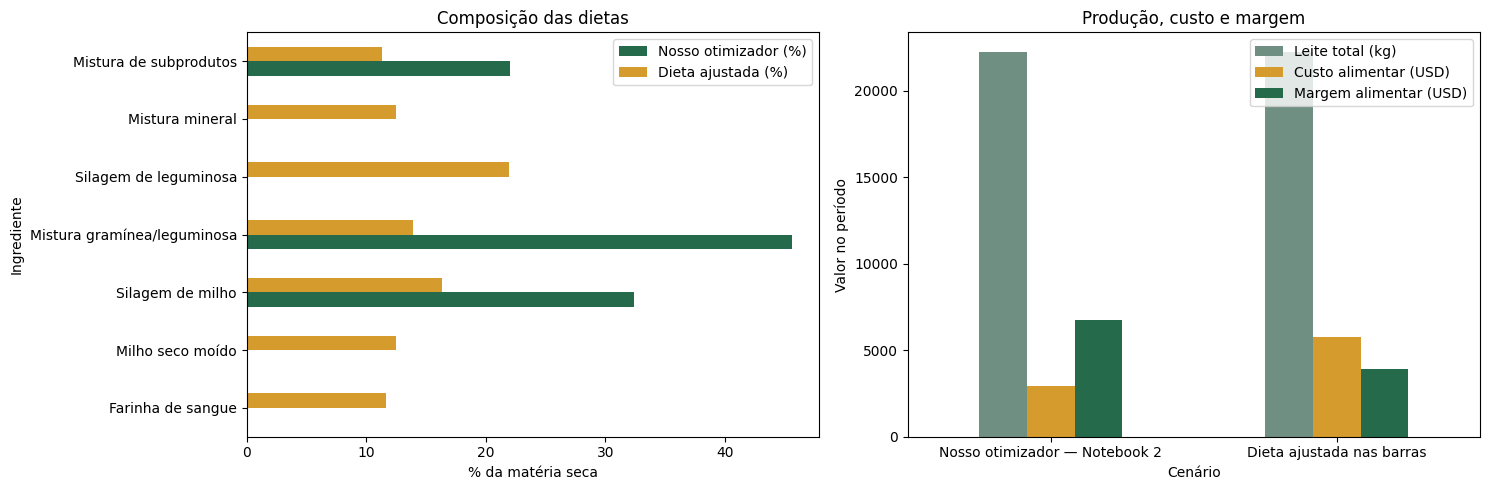

In [37]:
composition = (
    baseline_actual_ration[['feed_type', 'percentage_dm']]
    .merge(adjusted_actual_ration[['feed_type', 'percentage_dm']], on='feed_type', how='outer', suffixes=('_baseline', '_adjusted'))
    .fillna(0)
)
composition['Ingrediente'] = composition['feed_type'].map(names_pt)
composition_display = composition.rename(columns={
    'percentage_dm_baseline': 'Nosso otimizador (%)',
    'percentage_dm_adjusted': 'Dieta ajustada (%)',
})[['Ingrediente', 'Nosso otimizador (%)', 'Dieta ajustada (%)']]
show_table(
    composition_display, 'Composição média efetivamente simulada',
    formatter={
        'Nosso otimizador (%)': lambda value: format_pt_br(value, 2, '%'),
        'Dieta ajustada (%)': lambda value: format_pt_br(value, 2, '%'),
    },
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
composition_display.set_index('Ingrediente').plot.barh(ax=axes[0], color=['#256a4b', '#d59b2d'])
axes[0].set_title('Composição das dietas')
axes[0].set_xlabel('% da matéria seca')
axes[0].set_ylabel('Ingrediente')

performance[['Leite total (kg)', 'Custo alimentar (USD)', 'Margem alimentar (USD)']].plot.bar(ax=axes[1], color=['#6f8f82', '#d59b2d', '#256a4b'])
axes[1].set_title('Produção, custo e margem')
axes[1].set_ylabel('Valor no período')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()